# RFとGaussianNBの比較

訓練データから層化抽出した30,000件で5-fold交差検証とパラメータ選択を行う。選んだ特徴数とパラメータは固定し、最終モデルは学習データ全体172,459件で再学習する。k < 33の場合、MI順位は学習データ全体で計算する。保留テスト43,115件は各モデル1回だけ評価する。

主指標はAP。ROC-AUC、Accuracy、Precision、Recall、F1と処理時間も記録する。テスト結果を見て設定は変更しない。

## 1. ライブラリ、データ、共通の分割

In [1]:
from pathlib import Path
import sys
import time
import platform

experiment_started = time.perf_counter()
import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
get_ipython().run_line_magic("matplotlib", "inline")
# Use the macOS Japanese font when it is available.
japanese_font = Path("/System/Library/Fonts/ヒラギノ丸ゴ ProN W4.ttc")
if japanese_font.exists():
    font_manager.fontManager.addfont(str(japanese_font))
    plt.rcParams["font.family"] = font_manager.FontProperties(fname=str(japanese_font)).get_name()
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    RocCurveDisplay,
)
from sklearn.model_selection import (
    ParameterGrid,
    StratifiedKFold,
    train_test_split,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import OrdinalEncoder
from threadpoolctl import threadpool_limits

thread_limit = threadpool_limits(limits=1)

cwd = Path.cwd()
repo_root = cwd if (cwd / "src" / "preprocessing.py").exists() else cwd.parent
assert (repo_root / "src" / "preprocessing.py").exists(), (
    "Open this notebook from the project root or notebooks/ directory."
)
sys.path.insert(0, str(repo_root / "src"))
from preprocessing import NUMERIC_COLUMNS, build_preprocessor, prepare_xy, select_features

data_path = repo_root / "data" / "processed" / "census_income_adults.csv"
if not data_path.exists():
    import subprocess
    subprocess.run([sys.executable, "src/data_loader.py"], cwd=repo_root, check=True)

df = pd.read_csv(data_path, skipinitialspace=True)
X, y = prepare_xy(df)
X = select_features(X, include_migration=False)  # Baseline: 33 original features

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
X_dev, _, y_dev, _ = train_test_split(
    X_train, y_train, train_size=30_000, stratify=y_train, random_state=42
)
folds = list(StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
).split(X_dev, y_dev))

FEATURE_COUNTS = [5, 10, 15, 17, 20, 25, 33]
print(f"Python {platform.python_version()}; sklearn {sklearn.__version__}; pandas {pd.__version__}; numpy {np.__version__}")
print(f"元の特徴量数: {X.shape[1]}")
print(f"訓練行数: {len(X_train):,}; 保留テスト行数: {len(X_test):,}")
print(f"交差検証サンプル数: {len(X_dev):,}; 陽性率: {y_dev.mean():.4f}")
print(f"交差検証fold数: {len(folds)}; 特徴量数: {FEATURE_COUNTS}")

Python 3.13.12; sklearn 1.9.1; pandas 3.1.0; numpy 2.5.4
元の特徴量数: 33
訓練行数: 172,459; 保留テスト行数: 43,115
交差検証サンプル数: 30,000; 陽性率: 0.0861
交差検証fold数: 5; 特徴量数: [5, 10, 15, 17, 20, 25, 33]


## 2. 各foldでMI順位を作る

MIはone-hot化前の特徴量単位で計算する。数値列は中央値、カテゴリ列はMissingで補完し、MI計算用にOrdinalEncoderで数値化する。順位付けには各foldの学習データだけを使う。

In [2]:
def rank_features_by_mi(X_fit, y_fit):
    # Rank original features using only this fold's training rows.
    work = X_fit.copy()
    numeric = [column for column in NUMERIC_COLUMNS if column in work.columns]
    categorical = [column for column in work.columns if column not in numeric]

    if numeric:
        work[numeric] = SimpleImputer(strategy="median").fit_transform(work[numeric])
    if categorical:
        encoded = SimpleImputer(
            strategy="constant", fill_value="Missing"
        ).fit_transform(work[categorical])
        encoded = OrdinalEncoder(
            handle_unknown="use_encoded_value", unknown_value=-1
        ).fit_transform(encoded)
        work[categorical] = encoded

    discrete = [column in categorical for column in work.columns]
    scores = mutual_info_classif(
        work, y_fit, discrete_features=discrete,
        random_state=42, n_neighbors=3,
    )
    return (
        pd.DataFrame({"feature": work.columns, "MI": scores})
        .sort_values(["MI", "feature"], ascending=[False, True])
        .reset_index(drop=True)
    )

# Small preview; the actual CV ranks features within each fold.
display(rank_features_by_mi(X_dev.iloc[:1_000], y_dev.iloc[:1_000]).head(10))

,feature,MI
0,detailed_occupation_recode,0.086945
1,major_occupation_code,0.061866
2,detailed_industry_recode,0.060013
3,weeks_worked_in_year,0.049292
4,education,0.048986
5,major_industry_code,0.039343
6,sex,0.034031
7,class_of_worker,0.028454
8,tax_filer_stat,0.028141
9,num_persons_worked_for_employer,0.023196


## 3. 評価関数と初期設定でのモデル比較

In [3]:
def make_model(model_name, params=None):
    params = {} if params is None else dict(params)
    if model_name == "Random Forest":
        settings = {"n_estimators": 200, "random_state": 42, "n_jobs": 1}
        settings.update(params)
        return RandomForestClassifier(**settings)
    if model_name == "GaussianNB":
        settings = {"var_smoothing": 1e-9}
        settings.update(params)
        return GaussianNB(**settings)
    raise ValueError(f"Unknown model: {model_name}")


def run_cv(model_name, k, params=None):
    rows = []
    for fold_number, (train_idx, valid_idx) in enumerate(folds, start=1):
        X_fit, y_fit = X_dev.iloc[train_idx], y_dev.iloc[train_idx]
        X_valid, y_valid = X_dev.iloc[valid_idx], y_dev.iloc[valid_idx]

        mi_seconds = 0.0
        if k == X_dev.shape[1]:
            selected = list(X_fit.columns)
        else:
            started = time.perf_counter()
            ranking = rank_features_by_mi(X_fit, y_fit)
            selected = ranking["feature"].head(k).tolist()
            mi_seconds = time.perf_counter() - started

        X_fit_k, X_valid_k = X_fit[selected], X_valid[selected]
        preprocessor = build_preprocessor(X_fit_k, log_money=False)
        started = time.perf_counter()
        Z_fit = preprocessor.fit_transform(X_fit_k)
        Z_valid = preprocessor.transform(X_valid_k)
        if model_name == "GaussianNB":
            if hasattr(Z_fit, "toarray"):
                Z_fit, Z_valid = Z_fit.toarray(), Z_valid.toarray()
        preprocessing_seconds = time.perf_counter() - started

        model = make_model(model_name, params)
        started = time.perf_counter()
        model.fit(Z_fit, y_fit)
        fit_seconds = time.perf_counter() - started

        started = time.perf_counter()
        probability = model.predict_proba(Z_valid)[:, 1]
        predict_seconds = time.perf_counter() - started
        predicted = (probability >= 0.5).astype(int)
        tn, fp, fn, tp = confusion_matrix(
            y_valid, predicted, labels=[0, 1]
        ).ravel()

        rows.append({
            "model": model_name, "k": k, "fold": fold_number,
            "AP": average_precision_score(y_valid, probability),
            "ROC_AUC": roc_auc_score(y_valid, probability),
            "Accuracy": accuracy_score(y_valid, predicted),
            "Precision": precision_score(y_valid, predicted, zero_division=0),
            "Recall": recall_score(y_valid, predicted, zero_division=0),
            "F1": f1_score(y_valid, predicted, zero_division=0),
            "MI_seconds": mi_seconds,
            "preprocessing_seconds": preprocessing_seconds,
            "fit_seconds": fit_seconds,
            "predict_seconds": predict_seconds,
            "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        })
    return pd.DataFrame(rows)


all_folds = []
for model_name in ["Random Forest", "GaussianNB"]:
    for k in FEATURE_COUNTS:
        print(f"実行中: {model_name}、特徴量 {k} 個 ...", flush=True)
        all_folds.append(run_cv(model_name, k))

fold_results = pd.concat(all_folds, ignore_index=True)
summary = (
    fold_results.groupby(["model", "k"])
    .agg(
        AP_mean=("AP", "mean"), AP_sd=("AP", "std"),
        ROC_AUC_mean=("ROC_AUC", "mean"),
        Accuracy_mean=("Accuracy", "mean"),
        Precision_mean=("Precision", "mean"),
        Recall_mean=("Recall", "mean"), F1_mean=("F1", "mean"),
        MI_seconds_mean=("MI_seconds", "mean"),
        preprocessing_seconds_mean=("preprocessing_seconds", "mean"),
        fit_seconds_mean=("fit_seconds", "mean"),
        predict_seconds_mean=("predict_seconds", "mean"),
    )
    .reset_index()
)
display(summary.round(4))

実行中: Random Forest、特徴量 5 個 ...


実行中: Random Forest、特徴量 10 個 ...


実行中: Random Forest、特徴量 15 個 ...


実行中: Random Forest、特徴量 17 個 ...


実行中: Random Forest、特徴量 20 個 ...


実行中: Random Forest、特徴量 25 個 ...


... (5 outputs left out)

実行中: GaussianNB、特徴量 20 個 ...


実行中: GaussianNB、特徴量 25 個 ...


実行中: GaussianNB、特徴量 33 個 ...


,model,k,AP_mean,AP_sd,ROC_AUC_mean,Accuracy_mean,Precision_mean,Recall_mean,F1_mean,MI_seconds_mean,preprocessing_seconds_mean,fit_seconds_mean,predict_seconds_mean
0,GaussianNB,5,0.1676,0.0350,0.7359,0.4229,0.1233,0.9327,0.2178,0.5599,0.0272,0.0153,0.0029
1,GaussianNB,10,0.1423,0.0153,0.7029,0.4057,0.1216,0.9481,0.2156,0.4930,0.0438,0.0133,0.0037
2,GaussianNB,15,0.1324,0.0036,0.6865,0.4179,0.1254,0.9628,0.2218,0.4852,0.0580,0.0180,0.0041
3,GaussianNB,17,0.1332,0.0036,0.6886,0.4216,0.1260,0.9628,0.2229,0.5330,0.0699,0.0170,0.0043
4,GaussianNB,20,0.1161,0.0062,0.6371,0.3430,0.1132,0.9671,0.2027,0.5381,0.0812,0.0539,0.0095
5,GaussianNB,25,0.1037,0.0026,0.5903,0.2757,0.1028,0.9582,0.1856,0.5308,0.1046,0.0390,0.0112
6,GaussianNB,33,0.1039,0.0022,0.5910,0.2797,0.1031,0.9559,0.1861,0.0000,0.1750,0.0392,0.0103
7,Random Forest,5,0.4194,0.0360,0.8381,0.9175,0.5424,0.2721,0.3621,0.4853,0.0247,3.9710,0.0949
8,Random Forest,10,0.5043,0.0243,0.8796,0.9231,0.5830,0.3742,0.4554,0.4804,0.0385,6.8842,0.1076
9,Random Forest,15,0.5726,0.0159,0.9069,0.9306,0.6703,0.3843,0.4878,0.4789,0.0558,7.1205,0.1021


## 4. APと計算時間を比較

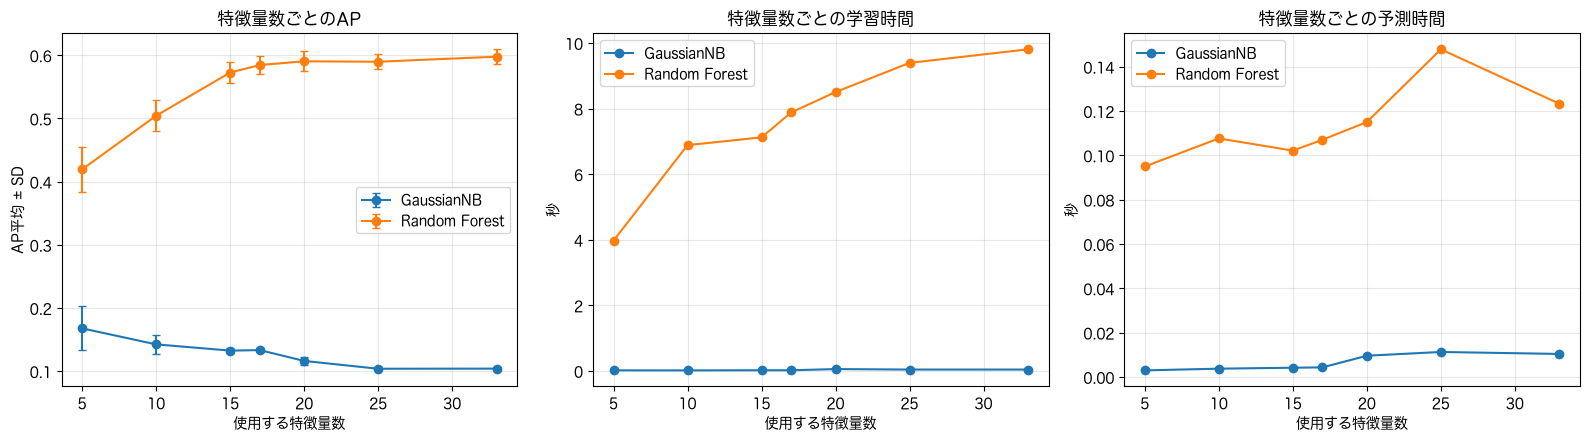

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for model_name, group in summary.groupby("model"):
    group = group.sort_values("k")
    axes[0].errorbar(group["k"], group["AP_mean"], yerr=group["AP_sd"], marker="o", capsize=3, label=model_name)
    axes[1].plot(group["k"], group["fit_seconds_mean"], marker="o", label=model_name)
    axes[2].plot(group["k"], group["predict_seconds_mean"], marker="o", label=model_name)
axes[0].set(title="特徴量数ごとのAP", xlabel="使用する特徴量数", ylabel="AP平均 ± SD")
axes[1].set(title="特徴量数ごとの学習時間", xlabel="使用する特徴量数", ylabel="秒")
axes[2].set(title="特徴量数ごとの予測時間", xlabel="使用する特徴量数", ylabel="秒")
for ax in axes:
    ax.legend()
    ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## 5. パラメータ調整

初期CVでAP平均が高かった特徴量数をモデルごとに選び、同じfoldでパラメータ候補を比較する。テストデータはこの段階では使わない。

In [5]:
chosen_k = (
    summary.sort_values(["model", "AP_mean", "k"], ascending=[True, False, True])
    .groupby("model", as_index=False).first()[["model", "k"]]
    .set_index("model")["k"].astype(int).to_dict()
)
print("初期CVのAP平均で選んだ特徴量数:", chosen_k)

parameter_grids = {
    "Random Forest": {
        "n_estimators": [200, 400],
        "max_depth": [None, 20],
        "min_samples_leaf": [1, 5],
    },
    "GaussianNB": {"var_smoothing": [1e-9, 1e-8, 1e-7, 1e-6]},
}

tuning_rows = []
for model_name, grid in parameter_grids.items():
    for params in ParameterGrid(grid):
        print(f"調整中: {model_name}、設定 {params}", flush=True)
        scores = run_cv(model_name, chosen_k[model_name], params=params)
        tuning_rows.append({
            "model": model_name,
            "k": chosen_k[model_name],
            "params": params,
            "AP_mean": scores["AP"].mean(),
            "AP_sd": scores["AP"].std(),
            "ROC_AUC_mean": scores["ROC_AUC"].mean(),
            "F1_mean": scores["F1"].mean(),
            "fit_seconds_mean": scores["fit_seconds"].mean(),
            "predict_seconds_mean": scores["predict_seconds"].mean(),
        })

tuning_summary = pd.DataFrame(tuning_rows)
best_tuning = (
    tuning_summary.sort_values(["model", "AP_mean"], ascending=[True, False])
    .groupby("model", as_index=False).first()
)
display(tuning_summary.sort_values(["model", "AP_mean"], ascending=[True, False]).round(4))
print("CVのAP平均で選んだ設定:")
display(best_tuning[["model", "k", "params", "AP_mean", "AP_sd"]])

初期CVのAP平均で選んだ特徴量数: {'GaussianNB': 5, 'Random Forest': 33}
調整中: Random Forest、設定 {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}


調整中: Random Forest、設定 {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 400}


調整中: Random Forest、設定 {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 200}


調整中: Random Forest、設定 {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 400}


調整中: Random Forest、設定 {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 200}


調整中: Random Forest、設定 {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 400}


... (5 outputs left out)

調整中: GaussianNB、設定 {'var_smoothing': 1e-06}


,model,k,params,AP_mean,AP_sd,ROC_AUC_mean,F1_mean,fit_seconds_mean,predict_seconds_mean
11,GaussianNB,5,{'var_smoothing': 1e-06},0.2241,0.0152,0.8000,0.2760,0.0122,0.0026
10,GaussianNB,5,{'var_smoothing': 1e-07},0.2082,0.0138,0.7887,0.2250,0.0095,0.0024
9,GaussianNB,5,{'var_smoothing': 1e-08},0.1872,0.0336,0.7621,0.2192,0.0094,0.0024
8,GaussianNB,5,{'var_smoothing': 1e-09},0.1676,0.0350,0.7359,0.2178,0.0138,0.0026
5,Random Forest,33,"{'max_depth': 20, 'min_samples_leaf': 1, 'n_es...",0.6238,0.0174,0.9218,0.4191,10.7603,0.1730
4,Random Forest,33,"{'max_depth': 20, 'min_samples_leaf': 1, 'n_es...",0.6222,0.0171,0.9212,0.4191,5.5153,0.0919
2,Random Forest,33,"{'max_depth': None, 'min_samples_leaf': 5, 'n_...",0.6194,0.0184,0.9228,0.3745,3.9479,0.0871
3,Random Forest,33,"{'max_depth': None, 'min_samples_leaf': 5, 'n_...",0.6191,0.0192,0.9233,0.3780,8.3589,0.1791
7,Random Forest,33,"{'max_depth': 20, 'min_samples_leaf': 5, 'n_es...",0.6183,0.0192,0.9221,0.3533,6.5019,0.1540
6,Random Forest,33,"{'max_depth': 20, 'min_samples_leaf': 5, 'n_es...",0.6175,0.0189,0.9219,0.3538,3.3507,0.0790


CVのAP平均で選んだ設定:


,model,k,params,AP_mean,AP_sd
0,GaussianNB,5,{'var_smoothing': 1e-06},0.224140,0.015238
1,Random Forest,33,"{'max_depth': 20, 'min_samples_leaf': 1, 'n_es...",0.623788,0.017416


## 6. 全学習データで再学習し、保留テストで最終評価

CVで選んだ特徴数と最良パラメータを使い、各モデルを学習データ全体（172,459件）で再学習する。k < 33の場合、特徴量のMI順位も学習データ全体から計算する。保留テスト43,115件は各モデル1回だけ評価する。混同行列のしきい値は0.5。テスト結果を見て設定を変更しない。

In [6]:
final_rows = []
final_predictions = {}
final_models = {}
final_fit_rows = {}

assert len(X_train) == 172_459
assert len(X_test) == 43_115

for _, choice in best_tuning.iterrows():
    model_name = choice["model"]
    k = int(choice["k"])
    params = choice["params"]

    # Reuse CV-selected k and parameters. Rank on all training rows for k < 33.
    mi_seconds = 0.0
    if k == X_train.shape[1]:
        selected = list(X_train.columns)
    else:
        started = time.perf_counter()
        selected = rank_features_by_mi(X_train, y_train)["feature"].head(k).tolist()
        mi_seconds = time.perf_counter() - started

    X_train_k, X_test_k = X_train[selected], X_test[selected]
    preprocessor = build_preprocessor(X_train_k, log_money=False)
    started = time.perf_counter()
    Z_train = preprocessor.fit_transform(X_train_k)
    Z_test = preprocessor.transform(X_test_k)
    if model_name == "GaussianNB" and hasattr(Z_train, "toarray"):
        Z_train, Z_test = Z_train.toarray(), Z_test.toarray()
    preprocessing_seconds = time.perf_counter() - started

    model = make_model(model_name, params)
    started = time.perf_counter()
    model.fit(Z_train, y_train)
    fit_seconds = time.perf_counter() - started
    started = time.perf_counter()
    probability = model.predict_proba(Z_test)[:, 1]
    predict_seconds = time.perf_counter() - started
    predicted = (probability >= 0.5).astype(int)
    final_models[model_name] = (model, preprocessor, selected)
    final_predictions[model_name] = (probability, predicted)
    final_fit_rows[model_name] = len(X_train)
    final_rows.append({
        "model": model_name, "k": k, "params": params,
        "training_rows": len(X_train), "test_rows": len(X_test),
        "MI_seconds": mi_seconds,
        "preprocessing_seconds": preprocessing_seconds,
        "fit_seconds": fit_seconds,
        "predict_seconds": predict_seconds,
        "AP": average_precision_score(y_test, probability),
        "ROC_AUC": roc_auc_score(y_test, probability),
        "Accuracy": accuracy_score(y_test, predicted),
        "Precision": precision_score(y_test, predicted, zero_division=0),
        "Recall": recall_score(y_test, predicted, zero_division=0),
        "F1": f1_score(y_test, predicted, zero_division=0),
    })

test_summary = pd.DataFrame(final_rows)
display(test_summary.round(4))

,model,k,params,training_rows,test_rows,MI_seconds,preprocessing_seconds,fit_seconds,predict_seconds,AP,ROC_AUC,Accuracy,Precision,Recall,F1
0,GaussianNB,5,{'var_smoothing': 1e-06},172459,43115,3.99,0.1225,0.0774,0.0110,0.3046,0.8344,0.7334,0.2224,0.8392,0.3516
1,Random Forest,33,"{'max_depth': 20, 'min_samples_leaf': 1, 'n_es...",172459,43115,0.00,0.9357,159.2915,1.2578,0.6583,0.9294,0.9356,0.8411,0.3108,0.4539


## 7. 混同行列とROC曲線

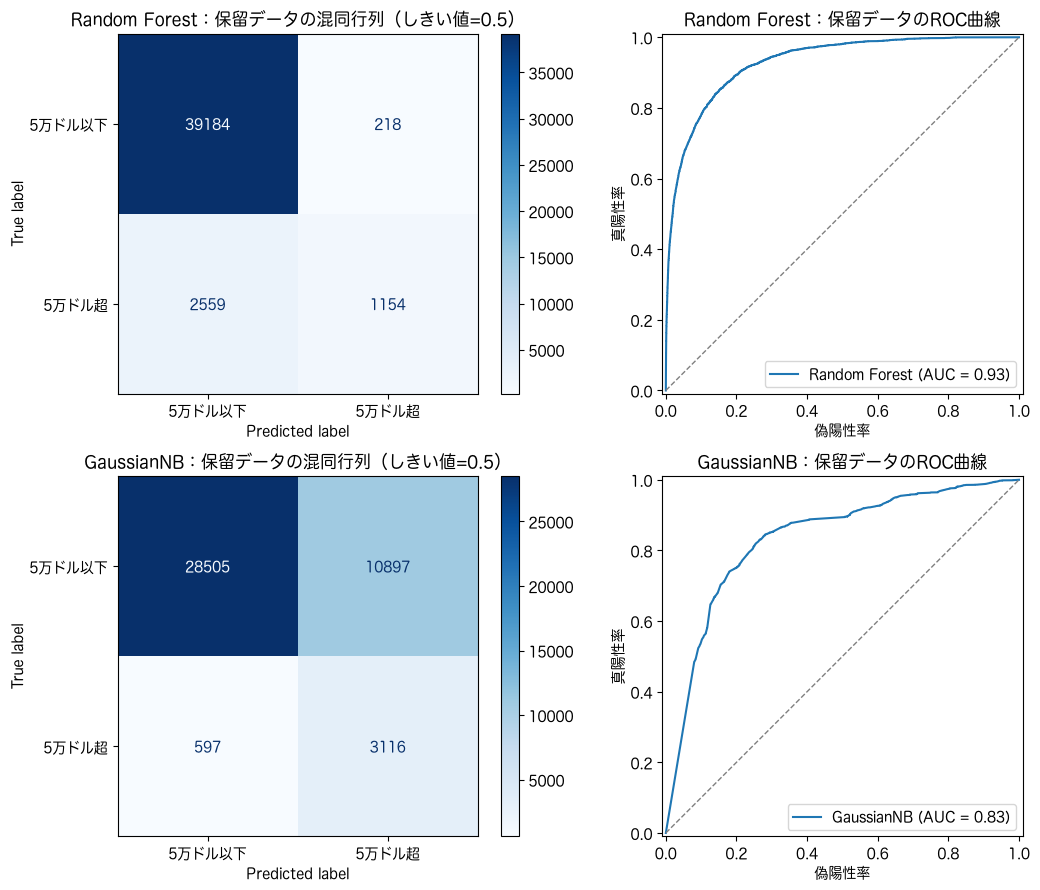

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for row, model_name in enumerate(["Random Forest", "GaussianNB"]):
    probability, predicted = final_predictions[model_name]
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicted, labels=[0, 1],
        display_labels=["5万ドル以下", "5万ドル超"],
        cmap="Blues", values_format="d", ax=axes[row, 0],
    )
    axes[row, 0].set_title(f"{model_name}：保留データの混同行列（しきい値=0.5）")
    RocCurveDisplay.from_predictions(y_test, probability, name=model_name, ax=axes[row, 1])
    axes[row, 1].plot([0, 1], [0, 1], linestyle="--", color="grey", linewidth=1)
    axes[row, 1].set_title(f"{model_name}：保留データのROC曲線")
    axes[row, 1].set_xlabel("偽陽性率")
    axes[row, 1].set_ylabel("真陽性率")
fig.tight_layout()
plt.show()

## 8. 最終確認

- 初期CVとパラメータ選択は30,000件、5-foldで実行した。
- 特徴量数は5、10、15、17、20、25、33。
- k < 33の場合、最終モデルのMI順位は172,459件の学習データ全体で計算した。
- 各モデルを学習データ全体で再学習し、43,115件のテストデータを各1回評価した。
- 保存した出力にエラーや警告がなく、すべてのassertが通ることを確認した。

In [8]:
assert len(X_train) == 172_459
assert len(X_test) == 43_115
assert X.shape[1] == 33
assert len(X_dev) == 30_000
assert len(folds) == 5
assert len(fold_results) == 70
assert fold_results.groupby(["model", "k"]).size().eq(5).all()
assert len(tuning_summary) == 12
assert set(test_summary["model"]) == {"Random Forest", "GaussianNB"}
assert test_summary["training_rows"].eq(172_459).all()
assert test_summary["test_rows"].eq(43_115).all()
assert final_fit_rows == {"Random Forest": 172_459, "GaussianNB": 172_459}
assert all(len(final_predictions[name][0]) == 43_115 for name in final_predictions)
print("最終確認が完了しました。")
print(f"交差検証結果の行数: {len(fold_results):,}（想定70行）")
print(f"調整した設定数: {len(tuning_summary):,}（想定12件）")
print(f"モデルごとの最終学習件数: {final_fit_rows}")
print(f"モデルごとの保留テスト件数: {len(X_test):,}")
total_seconds = time.perf_counter() - experiment_started
print(f"全体の実行時間: {total_seconds:.2f} 秒")

最終確認が完了しました。
交差検証結果の行数: 70（想定70行）
調整した設定数: 12（想定12件）
モデルごとの最終学習件数: {'GaussianNB': 172459, 'Random Forest': 172459}
モデルごとの保留テスト件数: 43,115
全体の実行時間: 842.43 秒
